In [13]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 3/6/2022
# version ='1.0'

# Demo: From Newton Method to Riccati Recursion in solving Linear Quadratic Regulator (LQR) 

Consider the time-varying optimal control problem,  

\begin{equation}
\begin{array}{rclcl}
\text{minimize} & & f(x)=\displaystyle{\sum_{t=1}^N}\phi_t(z_t) + \displaystyle{\sum_{t=0}^{N-1}}\psi_t(u_t) \\
\text{subject to} & & z(t+1)=A_tz_t+B_tu_t	& & t=0,1,...,N-1 \\
\end{array}
\end{equation}

where,
\begin{itemize}
\item The overall optimization variable $x$ is defined as
$$
x=[u_0^T, z_1^T, u_1^T, z_1^T, ..., u_{N-1}^T, z_{N}^T]^T \in \mathbf{R}^{N(k+l)}
$$
\item $z_t \in \mathbf{R}^k$ is the system state at time $t$
\item $u_t \in \mathbf{R}^l$ is the input at time $t$
\item $\phi_t: \mathbf{R}^k \rightarrow \mathbf{R}$ is the state cost function
\item $\psi_t: \mathbf{R}^l \rightarrow \mathbf{R}$ is the input cost function
\item $N$ is the discrete-time finite horizon
\item $z_0$ is the given initial system state
\end{itemize}

As discussed in [book-convex-2004], the optimal problem problem can be solved by the infeasible start Newton method, where a Newton step $\Delta x$ from a previous location $x^-$ is calculated from the KKT system equations

\begin{equation}
\begin{array}{rcl}
\left[\begin{array}{cc}
H(x^-) & A^T \\
A & 0
\end{array} \right]\left[\begin{array}{c}
\Delta x \\
w \\
\end{array} \right] & = & -\left[\begin{array}{c}
\nabla f(x^-) \\
Ax^--b \\
\end{array} \right]
\end{array}
\end{equation}
where
$$
\begin{array}{c}
H(x^-) = \nabla^2 f(x^-) = \mathbf{diag}(R_0, Q_1, R_1, Q_2, ..., R_{N-1}, Q_{N}) \\
\\
\begin{array}{cccc}
Q_t=\nabla^2 \phi_t(z_t^-) & t=1,2,...,N,  & R_t = \nabla^2 \psi_t(u_t^-) & t=0,1,...,N-1\\
\end{array} \\
\\
A=\left[\begin{array}{ccccccccc}
-B_0 & I & 0 & 0 & 0 & \cdots & 0 & 0 & 0 \\
0 & -A_1 & -B_1 & I & 0 & \cdots & 0 & 0 & 0 \\
0 & 0 & 0 & -A_2 & -B_2&  \cdots & 0 & 0 & 0 \\
\vdots & \vdots & \vdots & \vdots & \vdots & & \vdots & \vdots & \vdots \\
0 & 0 & 0 & 0 & 0 & \cdots & I & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & \cdots & -A_{N-1} & -B_{N-1} & I \\
\end{array} \right], b=\left[\begin{array}{c}
A_0z_0 \\
0 \\
0 \\
\vdots \\
0 \\
0 \\
\end{array} \right] \\
\end{array}
$$


By exploring the special block structure of $H(x^-)$ and $A$ using block elimination, the Newton step can be computed in order of $k^3N$ flops which grows linearly with the time horizon $N$.

In a special case when $\phi_t$ and $\psi_t$ are quadratic, i.e., 
\begin{equation}
\begin{array}{cccc}
\phi_t(z_t) = z_t^TQ_tz_t & t=1,...,N; & \psi_t(u_t) = u_t^TR_tu_t & t=0,1,...,N-1
\end{array}
\end{equation}  


It is the Linear Quadratic Regulator (LQR) in discrete-time finite horizon. In general, LQR can be solved by the Riccati Recursion derived from the dynamic programming (DP) principle (\cite{ee363}). This article will show that the Riccati Recursion can also be derived from solving the KKT system in the infeasible Newton method.

Because $\phi_t$ and $\psi_t$ are quadratic, the first-order approximation becomes an exact equation,
$$
\nabla f(x^-+\Delta x) = \nabla f(x^-) + \nabla^2 f(x^-) \Delta x 
$$
hence, $x^-+\Delta x$ is the exact optimal solution once $\Delta x$ is calculated whatever the starting point $x^-$ is. Specially, let $x^-=\mathbf{0}$, then 
$$
\begin{array}{ccc}
\nabla f(x^-)=0 & Ax^-=0 & H(x^-)=H=\mathbf{diag}(R_0, Q_1, R_1, Q_2, ..., R_{N-1}, Q_{N})\\
\end{array}
$$
The KKT solution can be simplified as

\begin{equation}
\begin{array}{rcl}
\left[\begin{array}{cc}
H & A^T \\
A & 0
\end{array} \right]\left[\begin{array}{c}
x \\
w \\
\end{array} \right] & = & -\left[\begin{array}{c}
0 \\
-b \\
\end{array} \right]
\end{array}
\end{equation}
where for convenience $\Delta x$ is replace by $x$ for better reading. After solving the equation, $x$ will be the exact optimal solution to the LQR, and it should be the same result as in the Newton method (i.e., $x^-+\Delta x)$. 

The following sections in the article will show that the equation can be solved in a recursive way without solving $w$ but still resulting in the same result as in Riccati Recursion.

The equation can be expanded into

\begin{equation}
Hx+A^Tw=0 \Rightarrow \left\{
\begin{array}{rcll}
R_tu_t & = & B_t^Tw_t & t=0,1,...,N-1 \\
Q_tz_t & = & -(w_{t-1}-A_t^Tw_t) & t=1,2,...,N-1 \\
Q_Nz_N & = & -w_{N-1} \\
\end{array}\right.
\end{equation}
\begin{equation}
\label{eq:NL39-kkt2-2}
Ax=b \Rightarrow \left\{
\begin{array}{rcll}
z_{t+1}& = & A_tz_t+B_tu_t & t=0,1,...,N-1 \\
\end{array}\right.
\end{equation}

Assuming $w_t=P_tz_{t+1}$ is true for some $t\leq N-1$ where $P_t\in \mathbf{S}^k$. This is guaranteed when $t=N-1$, because $w_{N-1}=P_{N-1}z_N$ by selecting $P_{N-1}=-Q_N$ according to the last equation. By substituting $z_{t+1}=A_tz_t+B_tu_t$ in $w_t=P_tz_{t+1}$, it results in
$$
w_t = P_t(A_tz_t+B_tu_t)
$$

By further substituting $u_t=R_t^{-1}B_t^Tw_t$ according to the first equation followed by some calculations, it results in
\begin{equation}
w_t = \left[I-P_tB_tR_t^{-1}B_t^T \right]^{-1}P_tA_tz_t
\end{equation}


Then by substituting $w_t$ in the second equation followed by some manipulations, it results in
\begin{equation}
\begin{array}{rclcl}
w_{t-1} = P_{t-1}z_t &\text{where} & P_{t-1}=-Q_t+A_t^T\left[I-P_tB_tR_t^{-1}B_t^T \right]^{-1}P_tA_t & & t=1,...,N
\end{array}
\end{equation}


Two matrix inversions are required when calculating $P_{t-1}$, but this can be further reduced by using the following matrix identity in substituting $Z\leftarrow R_t, Y\leftarrow B_t^T, X\leftarrow -P_tB_t$,
$$
(I+XZ^{-1}Y)^{-1}=I-X(Z+YX)^{-1}Y
$$
It leads to

\begin{equation}
\begin{array}{rcl}
P_{t-1} & = & -Q_t+A_t^T\left[I+P_tB_t\left(R_t-B_t^TP_tB_t \right)^{-1}B_t^T \right]P_tA_t \\
w_{t-1} & = & P_{t-1}z_t\text{{   ,where   }} t=1,2,...,N \\
\end{array}
\end{equation}


It is easy to verify that $P_{t-1}\in \mathbf{S}^k$ if $P_t \in \mathbf{S}^k$.

By substituting $w_t$ into the first equation, it results into
$$
u_t = R_t^{-1}B_t^Tw_t=R_t^{-1}B_t^T\left[I-P_tB_tR_t^{-1}B_t^T \right]^{-1}P_tA_tz_t
$$
The calculation $u_t$ from $z_t$ requires three matrix inversions, however, this number can be reduced to be one by using the following matrix identity and substituting $Y\leftarrow B_t^T, X\leftarrow P_tB_tR_t^{-1}$.
$$
Y(I-XY)^{-1} = (I-YX)^{-1}Y
$$
It leads to
\begin{equation}
\begin{array}{rclcl}
u_t = K_tz_t & \text{where} & K_t=\left[R_t-B_t^TP_tB_t \right]^{-1}B_t^TP_tA_t & & t=0,1,...,N-1 \\
\end{array}
\end{equation}

In summary, the LQR solution via solving the KKT system results in the same Riccati recursion algorithm as in the following:


# LQR solution via solving the Riccati Recursion Algorithm
\begin{enumerate}
\item set $P_N \leftarrow -Q_N$
\item for $t = N-1, N-2, ..., 1$,

$$
P_{t-1} \leftarrow -Q_t+A_t^T\left[I+P_tB_t\left(R_t-B_t^TP_tB_t \right)^{-1}B_t^T \right]P_tA_t
$$ 

\item for $t=0,1,...,N-1$,

$$
K_t \leftarrow \left[R_t-B_t^TP_tB_t \right]^{-1}B_t^TP_tA_t
$$

\item for $t=0,1,...,N-1$,

$$
\begin{array}{rcl}
u_t & \leftarrow & K_tz_t \\
z_{t+1} & \leftarrow & A_tz_t + B_tu_t \\ 
\end{array}
$$

\end{enumerate}

An experiment is simulated to compare the results to the results by directly solving the KKT system using matrix inversions. In the experiment, for all $t$, the model parameters are)

$$
\begin{array}{cccc}
A_t = \left[\begin{array}{cc}
1 & 1 \\
0 & 1 \\
\end{array} \right] & B_t=\left[\begin{array}{c}
0 \\
1 \\
\end{array} \right] & Q_t =\left[\begin{array}{cc}
1 & 0 \\
0 & 0 \\
\end{array} \right] & R_t = \rho I \\
\end{array}
$$

In [14]:
import numpy as np
from scipy.linalg import block_diag
import matplotlib.pyplot as plt

generate parameters for the specific problem described in the flexible lecture note

In [15]:
def get_problem_parameters(N, k, l, pho):
    """
    generate parameters for the specific problem described in the flexible lecture note
    :param N:
    :param k:
    :param l:
    :param pho:
    :return:
    """
    if k != 2 or l != 1:
        raise RuntimeError('only k=2, l=1 is supported')
    if l > k:
        raise RuntimeError('k should be equal or bigger than l')

    A = np.zeros((N, k, k))
    for i in range(N):
        A[i] = np.array([[1, 1], [0, 1]])

    B = np.zeros((N, k, l))
    for i in range(N):
        B[i] = np.array([[0], [1]])

    R = np.zeros((N, l, l))
    for i in range(N):
        R[i] = pho * np.identity(l)

    Q = np.zeros((N+1, k, k))
    for i in range(1, N+1):
        Q[i] = np.array([[1, 0], [0, 0]])

    z0 = np.array([[1], [0]])

    return A, B, Q, R, z0

solve the LQR problem by Riccati Recursion, that is
    $$
    \begin{array}{rcl}
    P_{t-1} & = & -Q_t+A_t^T\left[I+P_tB_t\left(R_t-B_t^TP_tB_t \right)^{-1}B_t^T \right]P_tA_t \\
    w_{t-1} & = & P_{t-1}z_t\text{{   ,where   }} t=1,2,...,N \\
    \end{array}
    $$
    $$
    \begin{array}{rclcl}
    u_t = K_tz_t & \text{where} & K_t=\left[R_t-B_t^TP_tB_t \right]^{-1}B_t^TP_tA_t & & t=0,1,...,N-1 \\
    \end{array}
    $$

In [16]:
def riccati_recursion(A, B, Q, R, z0):
    """
    solve the LQR problem by Riccati Recursion, that is
    $$
    \begin{array}{rcl}
    P_{t-1} & = & -Q_t+A_t^T\left[I+P_tB_t\left(R_t-B_t^TP_tB_t \right)^{-1}B_t^T \right]P_tA_t \\
    w_{t-1} & = & P_{t-1}z_t\text{{   ,where   }} t=1,2,...,N \\
    \end{array}

    \begin{array}{rclcl}
    u_t = K_tz_t & \text{where} & K_t=\left[R_t-B_t^TP_tB_t \right]^{-1}B_t^TP_tA_t & & t=0,1,...,N-1 \\
    \end{array}
    $$
    :param A:
    :param B:
    :param Q:
    :param R:
    :param z0:
    :return:
    """
    N = Q.shape[0]-1
    k = Q.shape[1]
    l = R.shape[1]

    Ik = np.identity(k)
    P = np.zeros((N, k, k))
    P[N-1] = -Q[N]

    for t in list(reversed(range(1, N))):
        P[t-1] = -Q[t] + A[t].T @ (Ik + P[t] @ B[t] @ np.linalg.inv(R[t]-B[t].T @ P[t] @ B[t]) @ B[t].T) @ P[t] @ A[t]

    K = np.zeros((N, l, k))
    for t in range(N):
        K[t] = np.linalg.inv(R[t] - B[t].T @ P[t] @ B[t]) @ B[t].T @ P[t] @ A[t]

    z = np.zeros((N+1, k, 1))
    z[0] = z0
    u = np.zeros((N, l, 1))
    for t in range(N):
        u[t] = K[t] @ z[t]
        z[t+1] = A[t] @ z[t] + B[t] @ u[t]

    return u, z

to get the LQR solution via solving the KKT system

refer to the flexible lecture note for more detail

In [17]:
def newton_method(A, B, Q, R, z0):
    """
    to get the LQR solution via solving the KKT system
    refer to the flexible lecture note for more detail
    :param A:
    :param B:
    :param Q:
    :param R:
    :param z0:
    :return:
    """
    N = Q.shape[0] - 1
    k = Q.shape[1]
    l = R.shape[1]
    blocks = []
    for t in range(N):
        blocks.append(R[t])
        blocks.append(Q[t+1])

    H = blocks[0]
    for i in range(1, len(blocks)):
        H = block_diag(H, blocks[i])

    Ik = np.identity(k)
    BIs = []
    for t in range(N):
        BIs.append(np.block([[-B[t], Ik]]))
    Ar = BIs[0]
    for i in range(1, len(BIs)):
        Ar = block_diag(Ar, BIs[i])

    Zeros = np.zeros((k, l))
    Zero_A = []
    for t in range(1, N):
        Zero_A.append(np.block([[Zeros, -A[t]]]))

    Al_tmp = Zero_A[0]
    for t in range(1, len(Zero_A)):
        Al_tmp = block_diag(Al_tmp, Zero_A[t])

    up_left = np.zeros((k, (N - 1) * (k + l)))
    down_right = np.zeros(((N - 1) * k, l + k))
    up_right = np.zeros((k, k+l))
    Al = np.block([[up_left, up_right], [Al_tmp, down_right]])

    big_A = Ar + Al
    b = np.block([[A[0] @ z0], [np.zeros(((N - 1) * k, 1))]])
    KKT = np.block([[H, big_A.T], [big_A, np.zeros((big_A.shape[0], big_A.shape[0]))]])
    residual = np.block([[np.zeros((N * (k+l), 1))], [b]])
    nu_w = np.linalg.inv(KKT) @ residual
    nu = nu_w[0: N * (k+l)]
    return nu

 get the external cost $\phi_t(z_t) = z_t^TQ_tz_t$
    and get the internal state transition cost, $\psi_t(u_t) = u_t^TR_tu_t$

In [18]:
def get_external_cost_internal_state_transition_cost(Q, R, u, z):
    """
    get the external cost $\phi_t(z_t) = z_t^TQ_tz_t$
    and get the internal state transition cost, $\psi_t(u_t) = u_t^TR_tu_t$
    :param Q:
    :param R:
    :param u:
    :param z:
    :return:
    """
    N = Q.shape[0]-1
    J_out = 0
    J_in = 0
    for t in range(1, N+1):
        J_out = J_out + (z[t].T @ Q[t] @ z[t]).item()

    for t in range(N):
        J_in = J_in + (u[t].T @ R[t] @ u[t]).item()

    return J_in, J_out

In [19]:
def plot_LQR_optimal_solutions_via_newton_method():
    N = 20
    k = 2
    l = 1
    rhos = [0.1, 10]
    plt.figure(figsize=(8, 4))
    ax1 = plt.subplot(2, 1, 1)
    ax2 = plt.subplot(2, 1, 2)
    markers = ['o', 's']
    for rho_i, rho in enumerate(rhos):

        A, B, Q, R, z0 = get_problem_parameters(N, k, l, rho)
        nu = newton_method(A, B, Q, R, z0)
        u_1 = np.zeros((N, l, 1))
        for t in range(N):
            u_1[t] = nu[(k+l) * t : (k+l) * t + l]

        z_1 = np.zeros((N+1, k, 1))
        z_1[0] = z0
        for t in range(1, N+1):
            z_1[t] = nu[(k+l) * (t-1) + l : (k+l) * t]

        #u_2, z_2 = riccati_recursion(A, B, Q, R, z0)
        # print('{}'.format(np.allclose(u_1, u_2)))
        # print('{}'.format(np.allclose(z_1, z_2)))

        C = np.array([[1, 0]])
        y = [(C @ z).item() for z in z_1]
        ax1.plot(np.squeeze(u_1), marker=markers[rho_i], fillstyle='none', label=r'$\rho$={}'.format(rho))
        ax2.plot(y, marker=markers[rho_i], fillstyle='none', label=r'$\rho$={}'.format(rho))

    ax1.grid()
    ax1.set_xticks(range(len(u_1)))
    ax1.legend()
    ax1.set_xlabel('t')
    ax1.set_ylabel(r'$u(t)$')

    ax2.grid()
    ax2.legend()
    ax2.set_xticks(range(len(z_1)))
    ax2.set_xlabel('t')
    ax2.set_ylabel(r'$y(t)=Q^{1/2}x(t)}$')

    plt.show()

In [20]:
def plot_pareto_optimal_J_in_J_out():
    N = 10
    k = 2
    l = 1
    rhos = np.exp(np.linspace(-1, 200, num=1000))
    plt.figure(figsize=(8, 4))
    ax1 = plt.subplot(1, 1, 1)

    J_in = []
    J_out = []
    J_in_interior = []
    J_out_interior = []
    for rho_i, rho in enumerate(rhos):

        A, B, Q, R, z0 = get_problem_parameters(N, k, l, rho)
        n_episode = 100
        mu, sigmas = 0, np.linspace(0.01, 0.1, num=5)  # mean and standard deviation
        for sigma in sigmas:
            for episode in range(n_episode):
                u = np.zeros((N, l, 1))
                z = np.zeros((N + 1, k, 1))
                z[0] = z0
                for t in range(N):
                    u[t] = np.random.normal(mu, sigma, (l, 1)) # np.random.uniform(-0.25, 0.25, (l, 1))
                    z[t + 1] = A[t] @ z[t] + B[t] @ u[t]

                j_in, j_out = get_external_cost_internal_state_transition_cost(Q, R, u, z)
                if j_in/rho < 0.2 and j_out < 10:
                    J_in_interior.append(j_in/rho)
                    J_out_interior.append(j_out)

        u, z = riccati_recursion(A, B, Q, R, z0)
        j_in, j_out = get_external_cost_internal_state_transition_cost(Q, R, u, z)
        J_in.append(j_in/rho)
        J_out.append(j_out)

    ax1.plot(J_in, J_out, marker='s', label=r'$(J^*_{in}(\rho), J^*_{out}(\rho))$')#, linestyle='None', marker='+')
    ax1.plot(J_in_interior, J_out_interior, linestyle='None', marker='x')
    ax1.set_xlim(-0.025, 0.2)
    ax1.set_ylim(0, 10)
    ax1.grid()
    ax1.legend()
    ax1.set_xlabel(r'$J_{in}$')
    ax1.set_ylabel(r'$J_{out}$')

    plt.show()

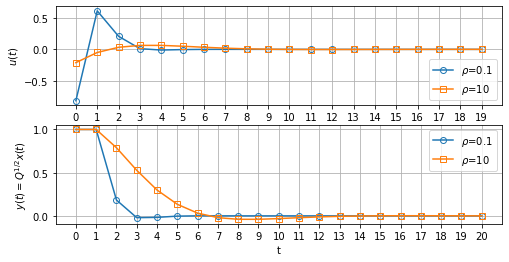

In [21]:
if __name__ == "__main__":
    plot_LQR_optimal_solutions_via_newton_method()

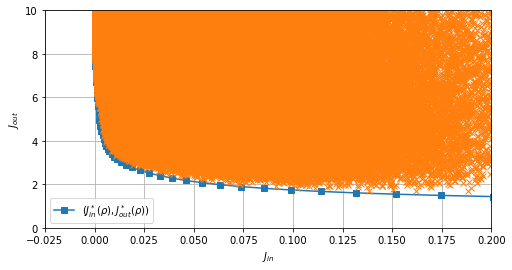

In [22]:
if __name__ == "__main__":
    plot_pareto_optimal_J_in_J_out()